<a href="https://colab.research.google.com/github/sugarfreecat/estatistica_descritiva/blob/main/notebooks/03_covariancia_e_correlacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![title](https://ik.imagekit.io/vzr6ryejm/colab/jupyter_notebook-cov_cor.drawio.png)

# 📙 Covariância e Correlação

### 🎯 O que você vai aprender
- **Variância** e desvio padrão (a base para o resto)
- **Covariância**: *para que lado* duas variáveis caminham juntas
- **Correlação**: *com que força* elas caminham juntas
- Como **interpretar** os resultados

### 💡 Dica
Sempre analisaremos **duas variáveis por vez**. Execute com **Shift + Enter**, de cima para baixo.

> ℹ️ Os textos de interpretação foram escritos para a **base padrão** (50 linhas, semente 21). Os números calculados nas células sempre se atualizam; se você gerar outra base, alguns comentários podem precisar de ajuste.

### 🔁 Lembrando
A **média** é a soma dos valores dividida pela quantidade, e o **desvio padrão** diz o quanto os valores se espalham em torno da média.

## 🔧 Preparação
Esta primeira célula carrega as ferramentas e os dados. Você só precisa executá-la.

### 📚 Importando as Bibliotecas

In [ ]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive          # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files          # (files) envia arquivos do seu computador para o Colab
                                        # obs.: "drive" aparece repetido, mas isso não causa problema

# Bibliotecas de análise de dados e de gráficos
import numpy as np                 # contas matemáticas (ex.: raiz quadrada)
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (10, 6)    # tamanho padrão dos gráficos (largura, altura)

### 🔄 Carregando a base de dados

In [ ]:
# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_colab = Path("/content/drive/MyDrive/Colab Notebooks") # pasta dos notebooks do Colab no Google Drive
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/estatistica/dados") # pasta onde a base de dados fica guardada no Drive
caminho_do_csv = pasta_dados / "alunos.csv"   # o "/" junta a pasta com o nome do arquivo

# ---------- 3) Se o arquivo ainda não existir, pede para você enviá-lo ----------
# Se o arquivo ainda não existir no Drive, pede o upload e grava na pasta indicada
if not caminho_do_csv.exists():                      # "not ... exists()" = "se NÃO existir"
    pasta_dados.mkdir(parents=True, exist_ok=True)   # cria a pasta "dados" se faltar
    print("Base não encontrada. Selecione o arquivo CSV para enviar:")
    enviados = files.upload()                        # abre o seletor de arquivos
    nome_enviado = next(iter(enviados))              # nome do arquivo escolhido
    shutil.move(nome_enviado, caminho_do_csv)        # move o arquivo enviado para a pasta de dados (alunos.csv)
    print(f"Arquivo salvo em: {caminho_do_csv}")

# ---------- 4) Lendo o arquivo e criando a tabela de dados ----------
dados = pd.read_csv(caminho_do_csv)   # lê o CSV e transforma em tabela (cada linha = um aluno)
dados.head()                          # mostra as 5 primeiras linhas para conferir se deu certo

Mounted at /content/drive


,id_aluno,curso,turno,mes_da_matricula,horas_estudo_semana,horas_sono_noite,numero_de_faltas,nota_final,renda_familiar_mensal,tempo_de_deslocamento_min,nota_diagnostico,aproveitamento_atividades_pct,nivel_engajamento
0,ALU-2664-EN,Saúde,Tarde,Jan,14.5,6.9,2,8.3,26709.31,45,7.5,70.5,Alto
1,ALU-1107-KJ,Direito,Tarde,Jan,15.4,8.2,2,8.5,5607.19,86,8.9,84.5,Alto
2,ALU-8645-CG,Engenharia,Noite,Abr,9.3,7.2,7,3.8,3604.23,24,3.2,57.6,Médio
3,ALU-0836-KV,Engenharia,Noite,Ago,6.1,7.1,4,4.3,2684.80,44,2.9,22.7,Baixo
4,ALU-7042-PH,Saúde,Tarde,Jan,20.2,6.4,1,8.8,2993.52,48,4.8,66.5,Alto


### 📶 Selecionando colunas específicas

In [ ]:
# Vamos usar só as colunas necessárias nesta sessão
# Os colchetes duplos [[ ]] servem para escolher mais de uma coluna ao mesmo tempo
# Todas as colunas escolhidas são NÚMEROS, que é o que covariância e correlação precisam
dados = dados[["horas_estudo_semana", "horas_sono_noite", "numero_de_faltas",
               "nota_final", "tempo_de_deslocamento_min", "renda_familiar_mensal"]]
dados.head()   # mostra as 5 primeiras linhas para conferir as colunas escolhidas

,horas_estudo_semana,horas_sono_noite,numero_de_faltas,nota_final,tempo_de_deslocamento_min,renda_familiar_mensal
0,14.5,6.9,2,8.3,45,26709.31
1,15.4,8.2,2,8.5,86,5607.19
2,9.3,7.2,7,3.8,24,3604.23
3,6.1,7.1,4,4.3,44,2684.80
4,20.2,6.4,1,8.8,48,2993.52


#### 📖 O que significa cada coluna

| Coluna | O que é | Unidade |
|---|---|---|
| `horas_estudo_semana` | quantas horas o aluno estuda por semana | horas |
| `horas_sono_noite` | quantas horas o aluno dorme por noite | horas |
| `numero_de_faltas` | quantas vezes o aluno faltou | quantidade |
| `nota_final` | nota do aluno no final do curso | pontos |
| `tempo_de_deslocamento_min` | tempo que o aluno leva para chegar à faculdade | minutos |
| `renda_familiar_mensal` | renda mensal da família do aluno | R$ |

#### 📝 Conclusão
- Cada **linha** da tabela é **um aluno** e cada **coluna** é uma **medida** desse aluno.
- As seis colunas são **números**. Isso é importante: covariância e correlação só funcionam com **números**.
- Repare que cada coluna tem uma **unidade diferente** (horas, quantidade, pontos, minutos, R$). Guarde essa ideia, ela será muito importante mais adiante.

## 1️⃣ Relações entre variáveis
Perguntas como estas aparecem o tempo todo:
- *Quem **estuda mais** tira **notas melhores**?*
- *Quem **dorme mais** vai melhor na prova?*

Para **responder com números** (e não com "achismo") usamos **covariância** e **correlação**. Mas antes, precisamos entender a variância.

## 2️⃣ Variância e desvio padrão
*Você já conheceu a variância no Notebook 1. Vamos revê-la com calma, porque ela é a base da covariância.*

A **variância** mede o quanto os pontos diferem da média. Como ela eleva as diferenças ao quadrado, o resultado fica em **unidades ao quadrado** (difícil de interpretar). O **desvio padrão** é a **raiz quadrada** da variância e **volta à unidade original**.

**Passo a passo:**
1. Encontre a **média**.
2. **Subtraia a média** de cada valor.
3. **Eleve ao quadrado** (para que desvios positivos e negativos não se cancelem).
4. **Some** e **divida por $n-1$** (é o padrão usado pelo Pandas; por enquanto, basta saber que é assim que se faz).

$$s^2 = \frac{\sum (x_i - \bar{x})^2}{n-1} \qquad\qquad s = \sqrt{s^2}$$

Vamos ver a conta com **6 alunos** primeiro:

### Calculando a Variância e o Desvio Padrão - 6 primeiros alunos

In [ ]:
# ---------- Conta passo a passo com as notas dos 6 primeiros alunos ----------
seis_notas = dados["nota_final"].head(6)           # .head(6) pega só as 6 primeiras notas
n = len(seis_notas)                                # n = quantidade de alunos (6)

media = seis_notas.mean()                          # passo 1: calcula a média das notas

# Cria uma tabela para mostrar cada etapa da conta, uma coluna por passo
tabela_da_conta = pd.DataFrame({"nota": seis_notas})
tabela_da_conta["nota - média"] = seis_notas - media               # passo 2: distância de cada nota até a média (pode ser negativa)
tabela_da_conta["(nota - média)²"] = (seis_notas - media) ** 2     # passo 3: eleva ao quadrado (** 2): nenhum valor fica negativo
display(tabela_da_conta.round(2))                                  # mostra a tabela com 2 casas decimais

soma_dos_quadrados = tabela_da_conta["(nota - média)²"].sum()      # passo 4: soma todos os quadrados
variancia = soma_dos_quadrados / (n - 1)                           # passo 4: divide por n-1
desvio_padrao = np.sqrt(variancia)                                 # raiz quadrada da variância = desvio padrão

# Mostra os resultados e confere se o Pandas chega ao mesmo valor
print(f"Média = {media:.2f}")
print(f"Variância = {soma_dos_quadrados:.2f} / {n - 1} = {variancia:.2f}   (unidade: pontos²)")
print(f"Desvio padrão = raiz de {variancia:.2f} = {desvio_padrao:.2f}   (unidade: pontos)")
print(f"Conferindo com o Pandas -> .var(): {seis_notas.var():.2f} | .std(): {seis_notas.std():.2f}")

,nota,nota - média,(nota - média)²
0,8.3,1.57,2.45
1,8.5,1.77,3.12
2,3.8,-2.93,8.60
3,4.3,-2.43,5.92
4,8.8,2.07,4.27
5,6.7,-0.03,0.00


Média = 6.73
Variância = 24.37 / 5 = 4.87   (unidade: pontos²)
Desvio padrão = raiz de 4.87 = 2.21   (unidade: pontos)
Conferindo com o Pandas -> .var(): 4.87 | .std(): 2.21


#### 📝 Conclusão
- A **média** das 6 notas é **6,73**. A coluna `nota - média` mostra **a que distância** cada aluno está dela:
  - o aluno com nota **3,8** está **2,93 pontos abaixo** da média (valor negativo);
  - o aluno com nota **8,8** está **2,07 pontos acima** da média (valor positivo);
  - o aluno com nota **6,7** está quase em cima da média (**−0,03**): ele quase não contribui para a dispersão.
- Ao **elevar ao quadrado**, todos os valores ficam positivos e as distâncias grandes pesam mais. Somando tudo e dividindo por $n-1$ chegamos à **variância: 4,87 pontos²**.
- Tirando a raiz quadrada, chegamos ao **desvio padrão: 2,21 pontos**. Em palavras simples: **nestes 6 alunos, as notas ficam, em geral, a cerca de 2,2 pontos da média**.
- O Pandas (`.var()` e `.std()`) deu **exatamente o mesmo resultado** da nossa conta. Isso confirma que entendemos o passo a passo.

### Calculando a Variância e o Desvio Padrão - Todos os alunos

In [ ]:
# Agora com os 50 alunos, o Pandas faz tudo sozinho
notas = dados["nota_final"]                      # separa a coluna de notas em uma variável
print(f"Variância: {notas.var():.2f} pontos²")   # .var() calcula a variância
print(f"Desvio padrão: {notas.std():.2f} pontos")  # .std() calcula o desvio padrão

Variância: 3.16 pontos²
Desvio padrão: 1.78 pontos


#### 📝 Conclusão
- Com os **50 alunos**, a variância é **3,16 pontos²** e o desvio padrão é **1,78 pontos**.
- Compare com os 6 primeiros alunos (desvio de 2,21): **o resultado muda conforme o grupo analisado**. Por isso é bom usar o maior número de alunos possível.
- Daqui para a frente, vamos usar sempre os **50 alunos** e deixar o Pandas fazer as contas.

### Gráfico - Desvio Padrão - Todos os alunos

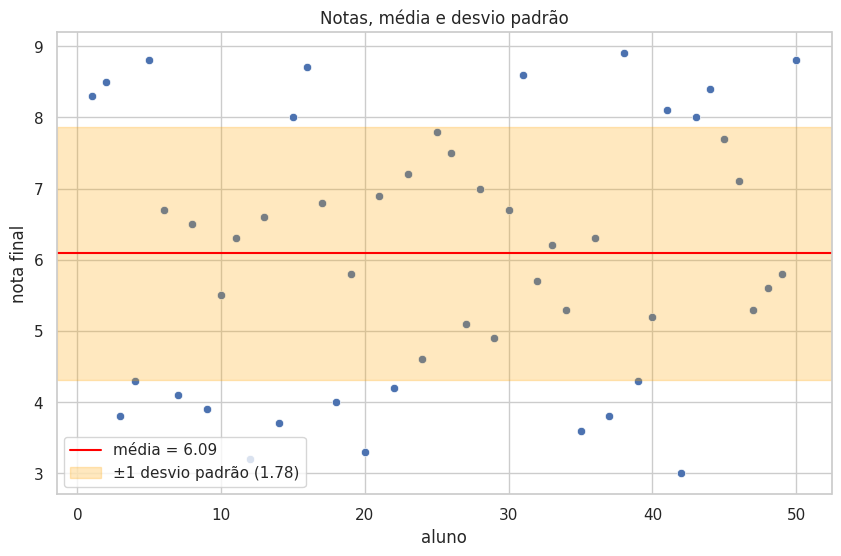

In [ ]:
# Visualizando: cada ponto é a nota de um aluno; a faixa laranja vai de (média - 1 desvio) até (média + 1 desvio)
media_geral = notas.mean()     # média das 50 notas
desvio_geral = notas.std()     # desvio padrão das 50 notas

sns.scatterplot(x=range(1, len(notas) + 1), y=notas)                  # um ponto por aluno: x = número do aluno (1 a 50), y = nota
plt.axhline(media_geral, color="red", label=f"média = {media_geral:.2f}")    # linha horizontal vermelha na altura da média
plt.axhspan(media_geral - desvio_geral, media_geral + desvio_geral, color="orange", alpha=0.25,   # faixa laranja: média ± 1 desvio
            label=f"±1 desvio padrão ({desvio_geral:.2f})")                                       # alpha = transparência da cor
plt.xlabel("aluno")                # nome do eixo horizontal
plt.ylabel("nota final")           # nome do eixo vertical
plt.title("Notas, média e desvio padrão")
plt.legend()                       # mostra a legenda (o que é a linha e o que é a faixa)
plt.show()

#### 📝 Conclusão

- A **variância** foi de **3,16 pontos²**. Ela mede a dispersão das notas em relação à média, utilizando os desvios elevados ao quadrado.

- **Por que elevamos os desvios ao quadrado?**  
  Porque os desvios podem ser **positivos ou negativos**. Um aluno com nota acima da média apresenta um desvio positivo, enquanto um aluno com nota abaixo da média apresenta um desvio negativo. Se simplesmente somássemos esses desvios, eles poderiam **se cancelar** e dar a impressão de que não existe dispersão.

  > **Exemplo:** Se a média fosse 6 pontos, uma nota 4 teria desvio −2, enquanto uma nota 8 teria desvio +2.

  $$-2 + (+2) = 0$$

  Nesse caso, os desvios se cancelariam. O resultado seria zero, mesmo existindo uma diferença de 2 pontos para cada lado da média.
  
  Ao elevar os desvios ao quadrado, todos se tornam positivos e passam a contribuir para o cálculo da variância.
  
  > Utilizando o mesmo exemplo anterior

  $$(−2)² + (+2)² = 4 + 4 = 8$$
  
  Ao elevar os desvios ao quadrado, os desvios não se cancelam. Desta forma, tanto os valores abaixo quanto os valores acima da média contribuem para medir a dispersão.

- O **desvio padrão** foi de **1,78 pontos**. Para obtê-lo, calculamos a raiz quadrada da variância: **√3,16 ≈ 1,78**.

- **Por que tiramos a raiz quadrada?**  
  Porque, ao elevar os desvios ao quadrado, a unidade também é elevada ao quadrado. Como as notas estão em **pontos**, a variância fica em **pontos²**. Ao calcular a raiz quadrada de **3,16 pontos²**, voltamos para a unidade original, obtendo **1,78 pontos**.

- Portanto, o **desvio padrão de 1,78 pontos** é a medida mais fácil de interpretar: as notas apresentam, em geral, uma distância de aproximadamente **1,78 ponto em relação à média**.

- **Lendo o gráfico:**
  - Cada **ponto** é um aluno. A **linha vermelha** é a média (**6,09**) e a **faixa laranja** vai de cerca de **4,3 a 7,9** (a média menos e mais 1 desvio padrão).
  - Notas **dentro da faixa** estão **perto da média**. Notas **fora da faixa** estão **mais longe**: no gráfico há alunos acima e abaixo dela, então as notas da turma são bem **variadas**.
  - Se todos os pontos estivessem colados na linha vermelha, o desvio padrão seria pequeno. Quanto mais **espalhados** os pontos, **maior** o desvio padrão.

## 3️⃣ Covariância
Mede **como duas variáveis mudam juntas**.

**Passo a passo:**
1. Escolha as duas variáveis (colunas), $X$ e $Y$.
2. **Subtraia a média** de cada uma: $(x_i - \bar{x})$ e $(y_i - \bar{y})$.
3. **Multiplique** as duas diferenças de cada aluno.
4. **Some** os produtos e **divida por $n-1$**.

$$cov(X,Y) = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{n-1}$$

| Resultado | O que significa |
|---|---|
| **Positiva** | as variáveis andam **na mesma direção** (uma sobe, a outra também) |
| **Negativa** | andam em **direções opostas** (uma sobe, a outra cai) |
| **Perto de zero** | **pouca ou nenhuma** relação |

> ⚠️ A covariância mostra só a **direção**, **não a força** da relação.

De novo, começamos com **6 alunos**: horas de estudo (X) e nota (Y).

### Cálculo da Covariância Horas de Estudo x Notas - 6 primeiros alunos

In [ ]:
# definindo o dataframe
tabela = dados[["horas_estudo_semana", "nota_final"]].head(6)

# selecionando x e y (horas de estudo semanal e nota final)
horas = tabela["horas_estudo_semana"] # X
notas = tabela["nota_final"] # Y

# novas colunas de subtração variável - média
tabela["horas - media"] = horas - horas.mean()
tabela["nota - media"] = notas - notas.mean()

# produto entre as colunas de subtração
tabela["produto"] = tabela["horas - media"] * tabela["nota - media"]

display(tabela.round(2))

soma_produtos = tabela["produto"].sum()

covariancia = soma_produtos / (len(tabela) - 1)
print(f"Covariância: {covariancia:.2f}")

print(f"Covariância calculada pelo Pandas: {horas.cov(notas):.2f}")

,horas_estudo_semana,nota_final,horas - media,nota - media,produto
0,14.5,8.3,1.62,1.57,2.53
1,15.4,8.5,2.52,1.77,4.45
2,9.3,3.8,-3.58,-2.93,10.51
3,6.1,4.3,-6.78,-2.43,16.51
4,20.2,8.8,7.32,2.07,15.12
5,11.8,6.7,-1.08,-0.03,0.04


Covariância: 9.83
Covariância calculada pelo Pandas: 9.83


#### 📝 Conclusão
Olhe a coluna **`produto`**: ela é o coração da covariância.

- Os alunos de **1, 2 e 5** estudam **mais que a média** e tiram nota **maior que a média** (as duas diferenças são positivas, então o produto é positivo).
- Os alunos **3 e 4** estudam **menos que a média** e tiram nota **menor que a média** (as duas diferenças são negativas, e **negativo × negativo = positivo**).
- O aluno **6** está quase na média nas duas variáveis, então o produto fica perto de **zero**.

| Situação do aluno | Produto | Quer dizer |
|---|---|---|
| os dois valores **acima** da média | positivo | "andam juntos" |
| os dois valores **abaixo** da média | positivo | "andam juntos" |
| um **acima** e o outro **abaixo** | negativo | "andam em sentidos opostos" |

Como **quase todos os produtos são positivos**, a soma é grande e positiva e a **covariância é 9,83**. Isso mostra que, nestes 6 alunos, **mais horas de estudo andam junto com notas maiores**.

> ⚠️ O número 9,83 mostra a **direção** (positiva), mas **não diz se a relação é forte ou fraca**. O Pandas (`.cov()`) deu o mesmo valor da nossa conta.

### Cálculo da Covariância Horas de Estudo x Notas - Todos os alunos

In [ ]:
horas_estudo = dados["horas_estudo_semana"]
notas = dados["nota_final"]

covariancia_50 = horas_estudo.cov(notas)
print(f"Covariância de todos os alunos: {covariancia_50:.2f}")

Covariância de todos os alunos: 6.88


### Gráfico da Covariância - Horas de Estudo x Notas - Todos os alunos

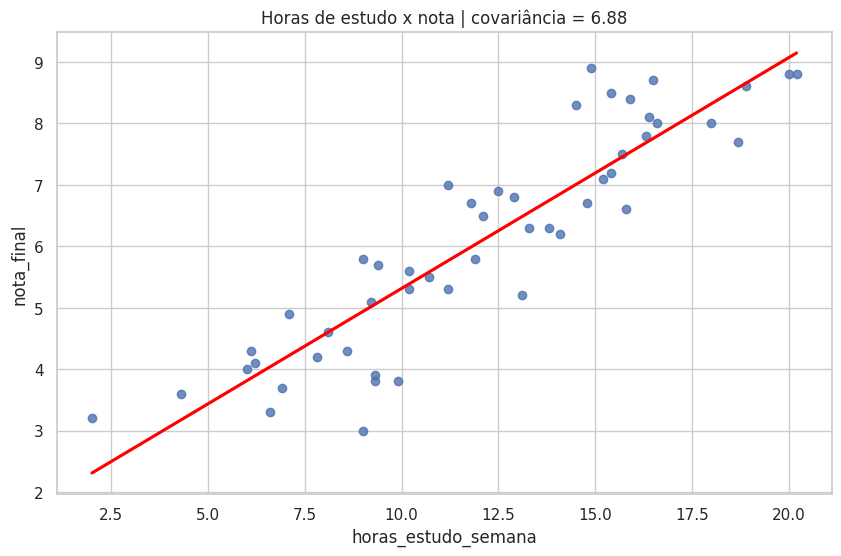

In [ ]:
# regplot = gráfico de dispersão (um ponto por aluno) + reta de tendência
# ci=None: sem faixa sombreada em volta da reta | line_kws: pinta a reta de vermelho
# Obs.: covariancia_50 guarda o valor calculado na célula acima (horas de estudo x nota)
sns.regplot(data=dados, x="horas_estudo_semana", y="nota_final", ci=None, line_kws={"color": "red"})
plt.title(f"Horas de estudo x nota | covariância = {covariancia_50:.2f}")   # {covariancia_50:.2f} escreve o número com 2 casas decimais
plt.show()

#### 📝 Conclusão: horas de estudo × nota
- A covariância é **+6,88**: o sinal é **positivo**, ou seja, **mais horas de estudo andam junto com notas maiores**.
- O gráfico mostra a mesma coisa: os pontos **sobem da esquerda para a direita** e a **reta de tendência vermelha também sobe**.
- Exemplo: quem estuda perto de **2 horas** por semana tira notas por volta de **3**; quem estuda perto de **20 horas** tira notas perto de **9**.
- A maior parte dos pontos fica **bem perto da reta**. Guarde essa observação: vamos medi-la com a correlação.

### Cálculo da Covariância Número de Faltas x Notas - Todos os alunos

### Gráfico da Covariância Número de Faltas x Notas - Todos os alunos

In [ ]:
# Mesmo tipo de gráfico: pontos (alunos) + reta de tendência vermelha
sns.regplot(data=dados, x="numero_de_faltas", y="nota_final", ci=None, line_kws={"color": "red"})
plt.title(f"Número de faltas x nota | covariância = {covariancia_50:.2f}")   # (título corrigido: antes dizia "Horas de estudo")
plt.show()

#### 📝 Conclusão: número de faltas × nota

### Cálculo da Covariância Tempo de Deslocamento x Notas - Todos os alunos

In [ ]:
tempo_de_deslocamento_min = dados["tempo_de_deslocamento_min"]   # coluna X (em minutos)
notas = dados["nota_final"]                                      # coluna Y (em pontos)

covariancia_50 = tempo_de_deslocamento_min.cov(notas)
print(f"Covariância (tempo_de_deslocamento_min x nota) = {covariancia_50:.2f}")

Covariância (tempo_de_deslocamento_min x nota) = -0.99


### Gráfico da Covariância Tempo de Deslocamento x Notas - Todos os alunos

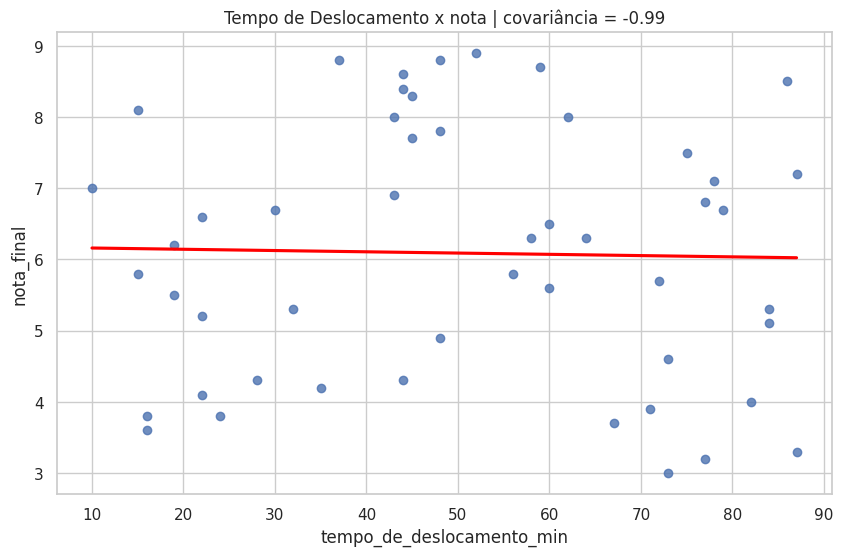

In [ ]:
# Mesmo tipo de gráfico: pontos (alunos) + reta de tendência vermelha
sns.regplot(data=dados, x="tempo_de_deslocamento_min", y="nota_final", ci=None, line_kws={"color": "red"})
plt.title(f"Tempo de Deslocamento x nota | covariância = {covariancia_50:.2f}")
plt.show()

#### 📝 Conclusão: tempo de deslocamento × nota

**Deslocamento × nota:** sinal negativo e valor menor que os outros dois, **mas isso é pouco ou muito?** O deslocamento é medido em *minutos* e a nota em *pontos*, e a covariância **depende da unidade**: não dá para julgar a força só olhando o número.

Para responder com segurança existe a **correlação**, que tira o efeito da unidade.

## 4️⃣ Correlação
Mede **a intensidade e a direção** da relação com um número **entre −1 e +1**. É a covariância **padronizada**: dividimos pelo produto dos desvios padrão.

**Passo a passo:**
1. Comece com a **covariância**.
2. Calcule o **desvio padrão** de cada variável.
3. **Divida** a covariância pelo produto dos desvios padrão.

$$r = \frac{cov(X,Y)}{s_X \cdot s_Y}$$

| Valor de $r$ | Significado |
|---|---|
| **+1** | correlação positiva **perfeita** |
| **−1** | correlação negativa **perfeita** |
| **0** | **sem** correlação |

**Guia de leitura:**
- $|r| < 0{,}3$ → fraca ou inexistente
- $0{,}3 \le |r| < 0{,}7$ → moderada
- $|r| \ge 0{,}7$ → forte

> 💡 Esses limites (0,3 e 0,7) são uma **regra prática** para facilitar a leitura, e não uma lei exata. O mais importante é olhar o **sinal** (direção) e o **tamanho** de $r$ (força).

### Cálculo da Correlação - Horas de Estudo x Notas

In [ ]:
# Passo 1: covariância (a mesma que calculamos antes)
covariancia = horas_estudo.cov(notas)

# Passo 2: desvio padrão de cada variável
desvio_das_horas = horas_estudo.std()
desvio_das_notas = notas.std()

# Passo 3: dividir a covariância pelo produto dos desvios (isso "tira" as unidades da conta)
r = covariancia / (desvio_das_horas * desvio_das_notas)

print(f"Covariância = {covariancia:.2f}")
print(f"Desvio padrão das horas = {desvio_das_horas:.2f} | Desvio padrão das notas = {desvio_das_notas:.2f}")
print(f"r = {covariancia:.2f} / ({desvio_das_horas:.2f} x {desvio_das_notas:.2f}) = {r:.2f}")
print(f"Conferindo com o Pandas -> .corr(): {horas_estudo.corr(notas):.2f}")   # .corr() calcula o r direto

Covariância = 6.88
Desvio padrão das horas = 4.28 | Desvio padrão das notas = 1.78
r = 6.88 / (4.28 x 1.78) = 0.90
Conferindo com o Pandas -> .corr(): 0.90


#### 📝 Conclusão
- Dividindo a covariância (**6,88**) pelo produto dos desvios (**4,28 × 1,78**), obtemos **r = 0,90**.
- O sinal é **positivo**: mais horas de estudo, nota maior. E o valor está **muito perto de +1**: a relação é **forte**. Isso combina com o gráfico, em que os pontos ficam **bem perto da reta que sobe**.
- Agora a pergunta "é pouco ou muito?" tem resposta: **0,90 é muito**. Com a covariância sozinha (6,88) não dava para dizer isso.
- O Pandas (`.corr()`) deu o mesmo resultado.

### Covariância × correlação na prática
Vamos medir as horas de estudo em **minutos** em vez de horas. A relação é a mesma, certo? Veja o que acontece:

In [ ]:
# Vamos medir as horas de estudo em MINUTOS em vez de horas: é a mesma informação, só muda a unidade
minutos_de_estudo = horas_estudo * 60       # 1 hora = 60 minutos

# Monta uma tabela comparando covariância e correlação nas duas unidades
comparacao = pd.DataFrame({
    "covariância": [horas_estudo.cov(notas), minutos_de_estudo.cov(notas)],
    "correlação (r)": [horas_estudo.corr(notas), minutos_de_estudo.corr(notas)],
}, index=["horas x nota", "minutos x nota"])
comparacao.round(2)    # arredonda para 2 casas decimais

,covariância,correlação (r)
horas x nota,6.88,0.9
minutos x nota,413.00,0.9


#### 📝 Conclusão
A **covariância ficou 60 vezes maior** só por mudar a unidade, e a **correlação não mudou**. Por isso a correlação permite **comparar** relações diferentes.

| | **Covariância** | **Correlação** |
|---|---|---|
| Mostra | só a **direção** | **direção e intensidade** |
| Depende da unidade? | **sim** | **não** (sempre de −1 a +1) |

## 5️⃣ Interpretando resultados
Vamos criar uma função que desenha a dispersão e **interpreta o $r$** para nós:

In [ ]:
def interpretar_r(r):
    # Traduz o valor de r em palavras (usando o guia de leitura da seção 4)
    # abs(r) = valor sem o sinal (-0,60 vira 0,60), pois a FORÇA não depende do sinal
    if abs(r) < 0.3:
        return "fraca ou inexistente"                      # menor que 0,3
    forca = "moderada" if abs(r) < 0.7 else "forte"        # de 0,3 a 0,7 = moderada | 0,7 ou mais = forte
    direcao = "positiva" if r > 0 else "negativa"          # o SINAL de r mostra a direção
    return f"{forca} {direcao}"

def desenhar_dispersao(coluna_x, coluna_y):
    # Recebe o nome de duas colunas, desenha o gráfico e devolve o valor de r
    r = dados[coluna_x].corr(dados[coluna_y])          # coeficiente de correlação entre as duas colunas
    sns.regplot(data=dados, x=coluna_x, y=coluna_y, ci=None, line_kws={"color": "red"})   # pontos + reta de tendência
    plt.title(f"{coluna_x} x {coluna_y}\nr = {r:.2f} ({interpretar_r(r)})")                # título com r e a interpretação em palavras
    plt.show()
    return r

### Caso 1: correlação positiva forte (Horas de Estudo x Nota Final)

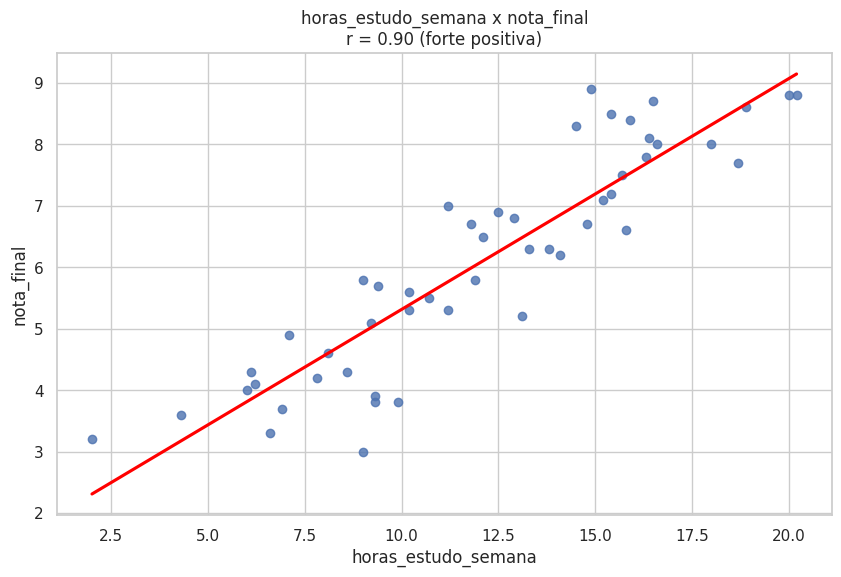

In [ ]:
# Caso 1: uso da função com horas de estudo e nota
# (r_horas_nota guarda o valor de r, caso queiramos usar depois)
r_horas_nota = desenhar_dispersao("horas_estudo_semana", "nota_final")

#### 📝 Conclusão
- **r = 0,90** (forte positiva). Os pontos formam uma **faixa estreita que sobe**, bem perto da reta.
- Quando conhecemos as horas de estudo de um aluno, conseguimos fazer uma **boa ideia** da nota dele.

### Caso 2: correlação negativa (Número de Faltas x Nota Final)

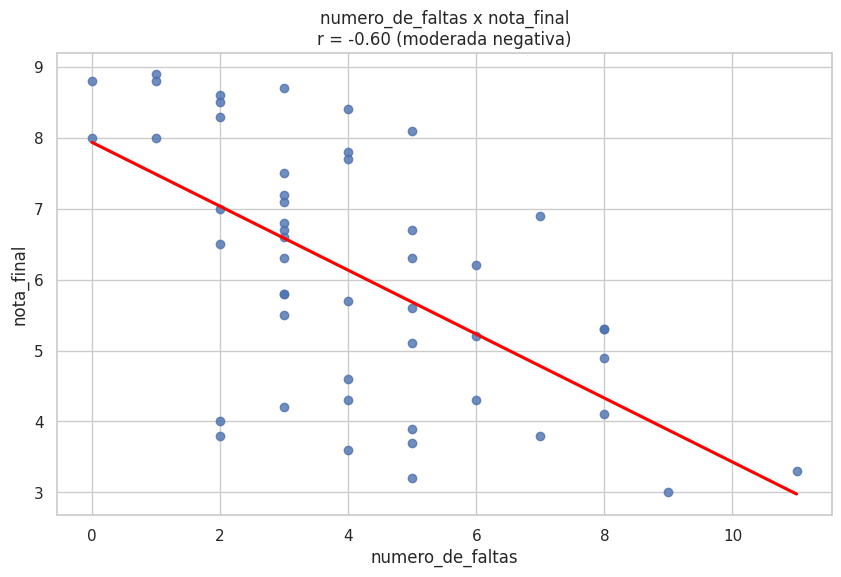

In [ ]:
# Caso 2: número de faltas e nota
r_faltas_nota = desenhar_dispersao("numero_de_faltas", "nota_final")

#### 📝 Conclusão

### Caso 3: correlação próxima de zero (Tempo de Deslocamento x Nota Final)

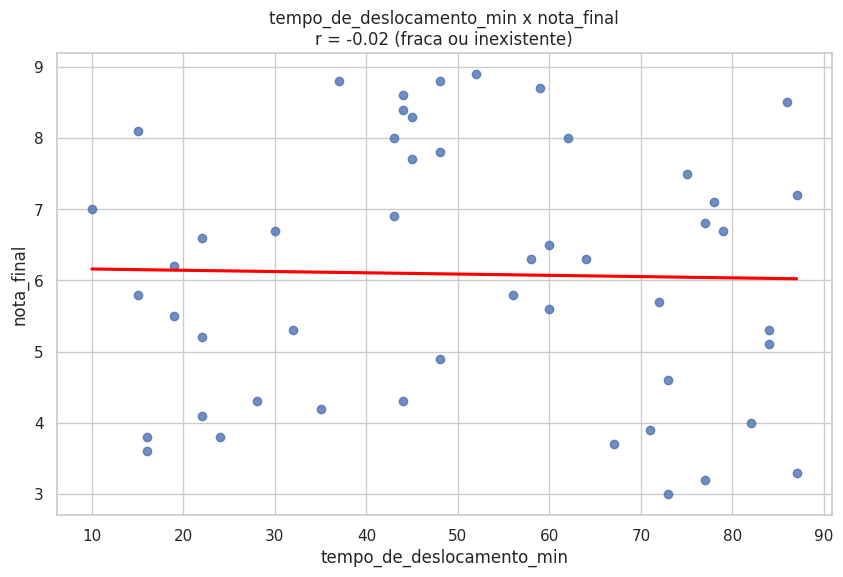

In [ ]:
# Caso 3: tempo de deslocamento e nota
r_deslocamento_nota = desenhar_dispersao("tempo_de_deslocamento_min", "nota_final")

#### 📝 Conclusão

### Para que serve no mundo real?
| Uso | Exemplo |
|---|---|
| **Encontrar relações** | como hábitos de estudo se ligam ao desempenho |
| **Prever mudanças** | estimar o efeito de estudar mais horas |
| **Negócios / instituições** | descobrir o que mais se associa ao bom resultado |
| **Pesquisa** | testar se a distância até a escola importa para a nota |
| **Decisões do dia a dia** | entender os próprios padrões e ajustar a rotina |

## 6️⃣ Prática: o sono influencia a nota?
Calcule a **covariância** e a **correlação** entre `horas_sono_noite` e `nota_final` e responda:
1. A covariância é positiva, negativa ou próxima de zero? O que isso sugere sobre a direção?
2. O $r$ é forte ou fraco? Positivo ou negativo?
3. O que o valor de $r$ diz sobre a relação entre sono e nota?
4. A direção faz sentido para você?
5. Como usar essa informação?

In [ ]:
sono = dados["horas_sono_noite"]      # coluna X: horas de sono por noite
notas = dados["nota_final"]           # coluna Y: nota final

covariancia_sono = sono.cov(notas)                                  # passo 1: covariância
r_sono = covariancia_sono / (sono.std() * notas.std())              # passos 2 e 3: divide pelo produto dos desvios

print(f"Covariância = {covariancia_sono:.2f}")
print(f"r = {covariancia_sono:.2f} / ({sono.std():.2f} x {notas.std():.2f}) = {r_sono:.2f}")

In [ ]:
# Mesma função de antes, agora com horas de sono e nota
r_sono = desenhar_dispersao("horas_sono_noite", "nota_final")

#### ✅ Resposta: o sono influencia a nota?
1. **Covariância:** **positiva** (**0,14**), mas é um número **muito pequeno**. Ela mostra só a **direção**: dormir mais anda **um pouquinho** junto com notas maiores. Ela **não mostra a força**.
2. **Valor de $r$:** **0,08**, positivo e **fraco ou inexistente** (menor que 0,3).
3. **O que $r$ diz:** valores perto de zero indicam que, **nesta turma**, o número de horas de sono **quase não ajuda a prever** a nota. No gráfico, a reta é **quase plana** e os pontos formam uma **nuvem**.
4. **Faz sentido?** Pelo senso comum, esperaríamos uma relação positiva. Mas os dados desta turma não mostram isso. Compare com as horas de estudo (**r = 0,90**): a diferença é enorme.
5. **Como usar essa informação:** para entender (e melhorar) as notas, vale olhar **primeiro** para os fatores com correlação mais forte: **horas de estudo** (0,90) e **faltas** (−0,60).

> 💡 Isso **não quer dizer** que dormir bem não importa. Quer dizer apenas que, **nestes 50 alunos**, o sono não aparece ligado à nota.

## 7️⃣ Cuidados na interpretação
### ⚠️ Correlação não é causalidade
Mesmo uma correlação forte entre estudo e nota **não prova** que estudar *causa* a nota alta: podem existir outros fatores.

### ⚠️ Outliers podem enganar
Veja a relação entre **renda** e **nota** com e sem os outliers da renda (regra de Tukey que você já conhece):

### Passo 01 - Cria uma nova coluna para identificar os outliers

In [ ]:
renda = dados["renda_familiar_mensal"]    # separa a coluna de renda

# Regra do box plot (a mesma da sessão anterior): quem está acima do limite superior é outlier
q1, q3 = renda.quantile(0.25), renda.quantile(0.75)     # q1 e q3 = quartis (marcam o início e o fim da "caixa" do box plot)
limite_superior = q3 + 1.5 * (q3 - q1)                  # (q3 - q1) é o tamanho da caixa
print(f"Limite superior: {limite_superior}")
dados["renda_e_outlier"] = renda > limite_superior       # cria uma nova coluna com True/False para cada aluno
dados.head()   # a última coluna mostra True para quem tem renda fora do padrão

Limite superior: 6502.526250000001


,horas_estudo_semana,horas_sono_noite,numero_de_faltas,nota_final,tempo_de_deslocamento_min,renda_familiar_mensal,renda_e_outlier
0,14.5,6.9,2,8.3,45,26709.31,True
1,15.4,8.2,2,8.5,86,5607.19,False
2,9.3,7.2,7,3.8,24,3604.23,False
3,6.1,7.1,4,4.3,44,2684.80,False
4,20.2,6.4,1,8.8,48,2993.52,False


### Passo 02 - Cria um novo DataFrame sem os outliers

In [ ]:
# ~ significa "não": ficam só os alunos em que renda_e_outlier é False (ou seja, SEM outliers)
sem_outliers = dados[~dados["renda_e_outlier"]]
sem_outliers.info()    # info() mostra um resumo da tabela: repare que sobraram 47 linhas (50 - 3 outliers)

<class 'pandas.core.frame.DataFrame'>
Index: 47 entries, 1 to 49
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   horas_estudo_semana        47 non-null     float64
 1   horas_sono_noite           47 non-null     float64
 2   numero_de_faltas           47 non-null     int64  
 3   nota_final                 47 non-null     float64
 4   tempo_de_deslocamento_min  47 non-null     int64  
 5   renda_familiar_mensal      47 non-null     float64
 6   renda_e_outlier            47 non-null     bool   
dtypes: bool(1), float64(4), int64(2)
memory usage: 2.6 KB


### Passo 03 - Calcula a Correlação de ambos os DataFrames

In [ ]:
# Correlação entre renda e nota: uma vez com todos os alunos e outra sem os outliers
r_com_outliers = dados["renda_familiar_mensal"].corr(dados["nota_final"])
r_sem_outliers = sem_outliers["renda_familiar_mensal"].corr(sem_outliers["nota_final"])

print(f"Outliers encontrados: {dados['renda_e_outlier'].sum()} alunos")   # soma dos True = quantidade de outliers
print(f"r COM os outliers = {r_com_outliers:.2f}")
print(f"r SEM os outliers = {r_sem_outliers:.2f}")

Outliers encontrados: 3 alunos
r COM os outliers = -0.04
r SEM os outliers = -0.20


#### 📝 Conclusão
- Foram encontrados **3 alunos** com renda fora do padrão.
- Com todos os alunos, **r = −0,04**. Sem os 3 outliers, **r = −0,20**. Nos dois casos a relação é **fraca** (menor que 0,3 em valor absoluto), então **renda e nota quase não se relacionam** nesta turma.
- Mesmo assim, **apenas 3 alunos (6% da turma)** mudaram o valor de r em **0,16**. Em outros conjuntos de dados, **poucos valores extremos** podem mudar muito mais o resultado.
- Por isso: **olhe o gráfico antes de confiar só no número**. E lembre-se: outlier **não é sinônimo de erro**. Investigue antes de decidir tirá-lo.

### Passo 04 - Gera o Gráfico identificando os outliers

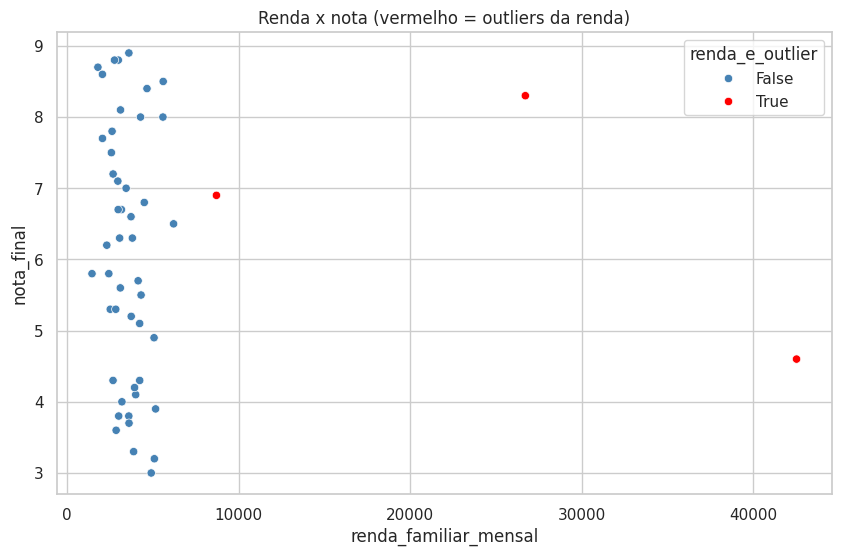

In [ ]:
# Os pontos vermelhos são os outliers
# hue = pinta os pontos de acordo com uma coluna (aqui, True/False de renda_e_outlier)
# palette = define a cor de cada valor: False = azul, True = vermelho
sns.scatterplot(data=dados, x="renda_familiar_mensal", y="nota_final", hue="renda_e_outlier",
                palette={False: "steelblue", True: "red"})
plt.title("Renda x nota (vermelho = outliers da renda)")
plt.show()

#### 📝 Conclusão
- Os pontos **azuis** ficam todos juntos, do lado esquerdo (rendas de até uns R$ 6.000). Os **três pontos vermelhos** ficam bem **longe, à direita**.
- Esses pontos isolados **esticam** o gráfico e podem **puxar** o valor de $r$ para um lado ou para o outro.
- Entre os azuis, **não há uma direção clara**: os pontos formam uma nuvem. Isso combina com a correlação **fraca** que calculamos.
- **Cuidado:** antes de interpretar uma correlação, **olhe o gráfico** e procure pontos muito distantes dos demais.

## ✅ Resumo da sessão
- **Variância** e **desvio padrão** medem a dispersão (o desvio volta à unidade original).
- **Covariância** mostra a **direção** da relação (positiva, negativa ou perto de zero), mas **não a força**.
- **Correlação ($r$)** mostra **direção e intensidade**, de −1 a +1, e permite comparar pares diferentes.
- **Correlação ≠ causalidade**, e **outliers** podem distorcer o resultado.

### 🧠 Conceito-chave
Para saber **o quanto** duas variáveis andam juntas, use a **correlação**; para saber **para que lado**, a covariância já responde.

---
## 🧭 Conclusões da sessão

### 1️⃣ Covariância e correlação em 3 passos
1. **Escolha** duas colunas numéricas (X e Y).
2. **Covariância:** veja se elas andam **juntas** (sinal positivo), em **sentidos opostos** (sinal negativo) ou **sem relação** (perto de zero).
3. **Correlação ($r$):** divida a covariância pelos desvios padrão para saber também a **força**, sem depender da unidade.

### 2️⃣ O que encontramos na turma (sempre contra a `nota_final`)
| Variável | Covariância | $r$ | Leitura |
|---|---|---|---|
| horas de estudo | +6,88 | **+0,90** | positiva **forte** |
| número de faltas | −2,53 | **−0,60** | negativa **moderada** |
| tempo de deslocamento | −0,99 | **−0,02** | **fraca ou inexistente** |
| horas de sono | +0,14 | **+0,08** | **fraca ou inexistente** |
| renda familiar | não calculada | **−0,04** | **fraca ou inexistente** |

> Repare: as **covariâncias** não podem ser comparadas entre si (cada variável tem uma unidade diferente). Já os valores de **$r$** podem.

### 3️⃣ Como ler o valor de $r$
| Valor de $r$ | Leitura | Como são os pontos |
|---|---|---|
| perto de **+1** | positiva forte | "linha" subindo, bem juntinha |
| perto de **−1** | negativa forte | "linha" descendo, bem juntinha |
| entre **0,3 e 0,7** (em valor absoluto) | moderada | faixa mais larga e solta |
| perto de **0** | fraca ou inexistente | nuvem sem direção |

### 4️⃣ Cuidados para não errar
- **Correlação não é causalidade:** estudar muito anda junto com notas altas, mas só a correlação não prova que um **causa** o outro.
- **Outliers** podem enganar: olhe sempre o gráfico antes de confiar no número.
- **Poucos dados** (aqui, 50 alunos) dão **pistas**, e não certezas.
- Compare sempre **correlações** (e não covariâncias) quando as unidades forem diferentes.

🎉 **Parabéns!** Você concluiu as 3 sessões de introdução à estatística descritiva.